In [20]:
import fastf1
import fastf1.plotting
import pandas as pd
import plotly.express as px

In [21]:
battle = fastf1.get_session(2026, 'Mexico', 'R')
battle.load()

core           INFO 	Loading data for Mexico City Grand Prix - Race [v3.9.2]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
core        WARNING 	Fixed incorrect tyre stint information for driver '30'
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 22 drivers: ['3', '44', '12', '16', '1', '63', '30', '5', '6', '50', '23', '55', '81', '27', '43', '11', '10', 

In [22]:
lecl1 = battle.laps.pick_drivers('LEC').pick_laps(1)

In [23]:
lecl1

,Time,Driver,DriverNumber,LapTime,LapNumber,Stint,PitOutTime,PitInTime,Sector1Time,Sector2Time,...,FreshTyre,Team,LapStartTime,LapStartDate,TrackStatus,Position,Deleted,DeletedReason,FastF1Generated,IsAccurate
168,0 days 00:14:47.915000,LEC,16,0 days 00:01:25.157000,1.0,1.0,NaT,NaT,NaT,0 days 00:00:32.842000,...,True,Ferrari,0 days 00:13:22.499000,2026-11-01 20:03:25.511,12,1.0,False,,False,False


In [24]:
haml1 = battle.laps.pick_drivers('HAM').pick_laps(1)

In [25]:
haml1

,Time,Driver,DriverNumber,LapTime,LapNumber,Stint,PitOutTime,PitInTime,Sector1Time,Sector2Time,...,FreshTyre,Team,LapStartTime,LapStartDate,TrackStatus,Position,Deleted,DeletedReason,FastF1Generated,IsAccurate
56,0 days 00:14:49.319000,HAM,44,0 days 00:01:26.561000,1.0,1.0,NaT,NaT,NaT,0 days 00:00:34.129000,...,False,Ferrari,0 days 00:13:22.499000,2026-11-01 20:03:25.511,12,3.0,False,,False,False


In [26]:
lecl1 = lecl1.get_car_data().add_distance()

In [27]:
haml1 = haml1.get_car_data().add_distance()

In [43]:
haml1

,Date,RPM,Speed,nGear,Throttle,Brake,DRS,Source,Time,SessionTime,Distance
0,2026-11-01 20:03:25.770,11557.0,0.0,1,23.0,False,1,car,0 days 00:00:00.259000,0 days 00:13:22.758000,0.000000
1,2026-11-01 20:03:26.250,8234.0,16.0,1,22.0,False,1,car,0 days 00:00:00.739000,0 days 00:13:23.238000,2.133333
2,2026-11-01 20:03:26.530,6274.0,19.0,1,22.0,False,1,car,0 days 00:00:01.019000,0 days 00:13:23.518000,3.611111
3,2026-11-01 20:03:26.850,4902.0,37.0,1,22.0,False,1,car,0 days 00:00:01.339000,0 days 00:13:23.838000,6.900000
4,2026-11-01 20:03:27.290,5755.0,51.0,1,35.0,False,1,car,0 days 00:00:01.779000,0 days 00:13:24.278000,13.133333
...,...,...,...,...,...,...,...,...,...,...,...
252,2026-11-01 20:04:50.810,12011.0,223.0,5,100.0,False,49,car,0 days 00:01:25.299000,0 days 00:14:47.798000,3951.096667
253,2026-11-01 20:04:51.130,10666.0,231.0,6,100.0,False,177,car,0 days 00:01:25.619000,0 days 00:14:48.118000,3971.630000
254,2026-11-01 20:04:51.410,10980.0,240.0,6,100.0,False,177,car,0 days 00:01:25.899000,0 days 00:14:48.398000,3990.296667
255,2026-11-01 20:04:51.650,11242.0,247.0,6,100.0,False,177,car,0 days 00:01:26.139000,0 days 00:14:48.638000,4006.763333


In [56]:
track = battle.get_circuit_info().corners
track

,X,Y,Number,Letter,Angle,Distance
0,11549.390625,-620.416504,1,,26.961071,1196.637082
1,11579.570557,-1334.711426,2,,-161.456631,1271.555022
2,11984.500977,-1769.020264,3,,26.924667,1325.675376
3,8811.018692,-7835.065430,4,,-166.079314,2019.384938
4,9258.899475,-8332.687500,5,,-0.292552,2092.646533
5,8180.223450,-9021.795898,6,,-109.046015,2220.299002
6,8337.142670,-5797.260254,7,,25.060337,2561.691906
7,7521.641602,-5024.284180,8,,-141.619777,2669.787104
8,7078.690796,-4423.575684,9,,50.280962,2740.661564
9,5329.669922,-3929.691406,10,,-128.913482,2930.856628


In [70]:
speed = 'Speed'

In [71]:
telem = pd.concat([
    lecl1[['Distance', speed]].assign(Driver='LEC'),
    haml1[['Distance', speed]].assign(Driver='HAM'),
], ignore_index=True)

In [72]:
telem

,Distance,Speed,Driver
0,0.000000,0.0,LEC
1,1.600000,12.0,LEC
2,3.077778,19.0,LEC
3,5.655556,29.0,LEC
4,11.400000,47.0,LEC
...,...,...,...
505,3951.096667,223.0,HAM
506,3971.630000,231.0,HAM
507,3990.296667,240.0,HAM
508,4006.763333,247.0,HAM


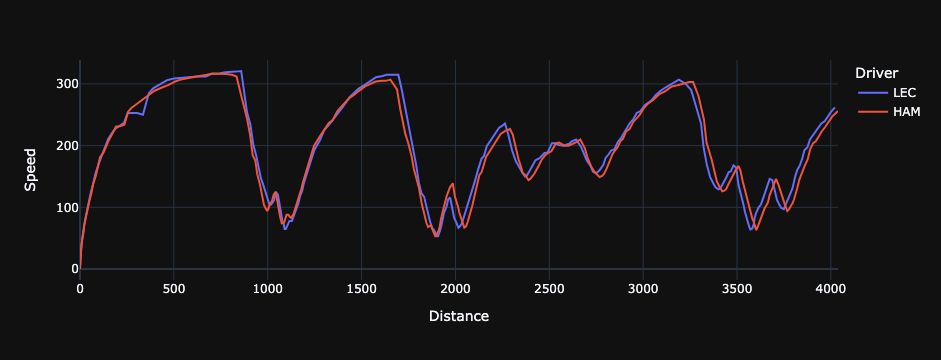

In [73]:
speed = px.line(
    telem,
    x='Distance',
    y=speed,
    color='Driver',
    template='plotly_dark'
)
speed.show()

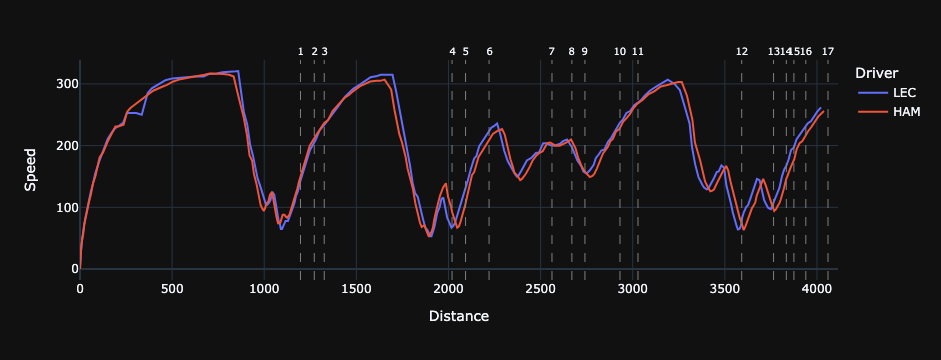

In [74]:
for _, corner in track.iterrows():
    speed.add_vline(
        x=corner['Distance'],
        line_dash='dash',
        line_color='gray',
        line_width=1,
        annotation_text=f"{corner['Number']}{corner['Letter']}",
        annotation_position='top',
        annotation_font_size=10
    )
   
speed.update_layout(hovermode='x unified')
speed.show()

In [63]:
throttle = 'Throttle'

In [67]:
telem2 = pd.concat([
    lecl1[['Distance', throttle]].assign(Driver='LEC'),
    haml1[['Distance', throttle]].assign(Driver='HAM')
], ignore_index=True)

In [68]:
telem2

,Distance,Throttle,Driver
0,0.000000,32.0,LEC
1,1.600000,31.0,LEC
2,3.077778,31.0,LEC
3,5.655556,36.0,LEC
4,11.400000,39.0,LEC
...,...,...,...
505,3951.096667,100.0,HAM
506,3971.630000,100.0,HAM
507,3990.296667,100.0,HAM
508,4006.763333,100.0,HAM


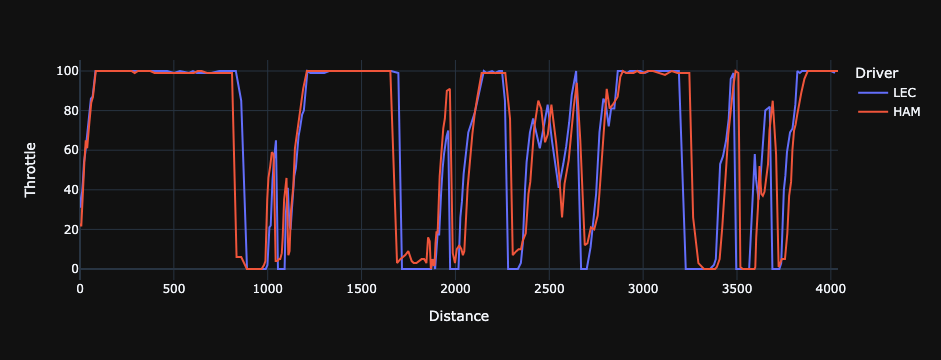

In [75]:
throttle = px.line(
    telem2,
    x='Distance',
    y=throttle,
    color='Driver',
    template='plotly_dark'
)
throttle.show()

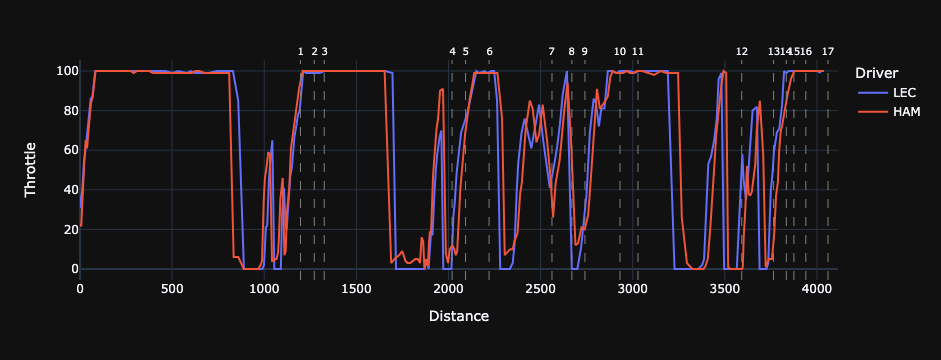

In [77]:
for _, corner in track.iterrows():
    throttle.add_vline(
        x=corner['Distance'],
        line_dash='dash',
        line_color='gray',
        line_width=1,
        annotation_text=f"{corner['Number']}{corner['Letter']}",
        annotation_font_size=10,
        annotation_position='top'
    )
throttle.update_layout(hovermode='x unified')
throttle.show()

In [78]:
brake = 'Brake'

In [82]:
telem3 = pd.concat([
    lecl1[['Distance', brake]].assign(Driver='LEC'),
    haml1[['Distance', brake]].assign(Driver='HAM'),
], ignore_index=True)
telem3

,Distance,Brake,Driver
0,0.000000,False,LEC
1,1.600000,False,LEC
2,3.077778,False,LEC
3,5.655556,False,LEC
4,11.400000,False,LEC
...,...,...,...
505,3951.096667,False,HAM
506,3971.630000,False,HAM
507,3990.296667,False,HAM
508,4006.763333,False,HAM


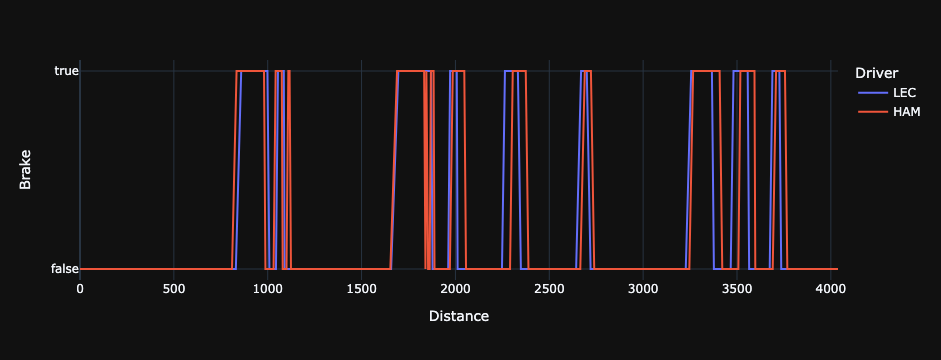

In [83]:
brake = px.line(
    telem3,
    x='Distance',
    y=brake,
    color='Driver',
    template='plotly_dark'
)
brake.show()

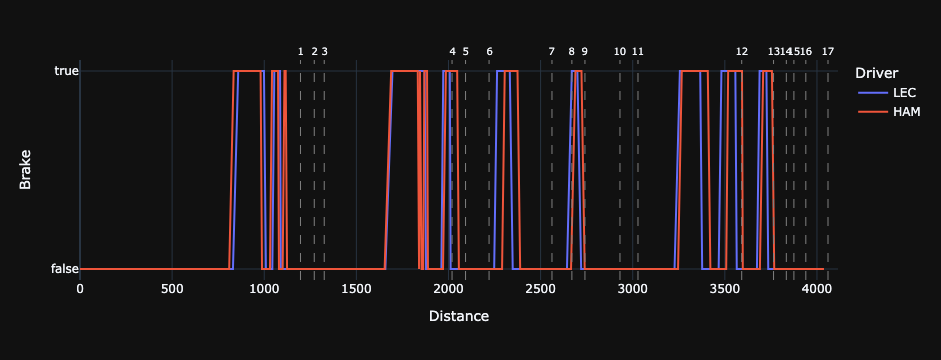

In [87]:
for _, corner in track.iterrows():
    brake.add_vline(
    x=corner['Distance'],
    line_dash='dash',
    line_width=1,
    line_color='gray',
    annotation_text=f"{corner['Number']}{corner['Letter']}",
    annotation_font_size=10,
    annotation_position='top'
)
brake.update_layout(hovermode='x unified')
brake.show()

In [90]:
telem4 = pd.concat([
    lecl1[['Distance', 'nGear']].assign(Driver='LEC'),
    haml1[['Distance', 'nGear']].assign(Driver='HAM')
], ignore_index=True)
telem4

,Distance,nGear,Driver
0,0.000000,1,LEC
1,1.600000,1,LEC
2,3.077778,1,LEC
3,5.655556,1,LEC
4,11.400000,1,LEC
...,...,...,...
505,3951.096667,5,HAM
506,3971.630000,6,HAM
507,3990.296667,6,HAM
508,4006.763333,6,HAM


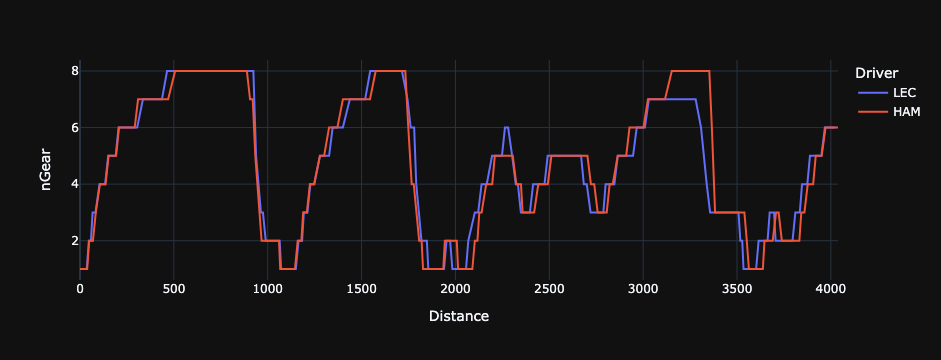

In [91]:
gear = px.line(
    telem4,
    x='Distance',
    y='nGear',
    color='Driver',
    template='plotly_dark'
)
gear.show()

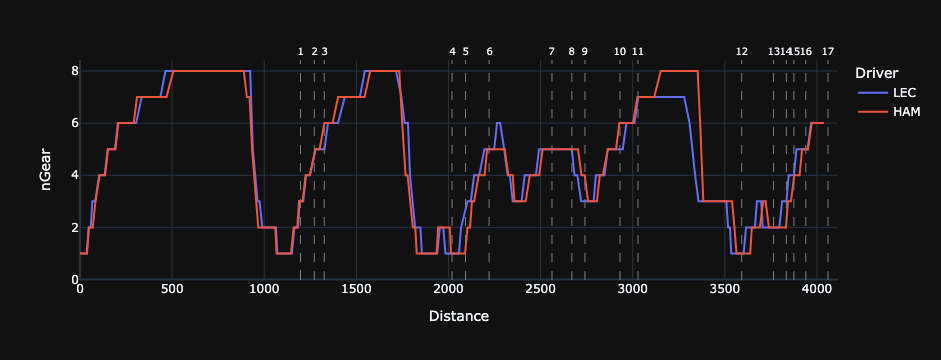

In [96]:
for _, corner in track.iterrows():
    gear.add_vline(
        x=corner['Distance'],
        line_dash='dash',
        line_color='gray',
        line_width=1,
        annotation_text=f"{corner['Number']}{corner['Letter']}",
        annotation_position='top',
        annotation_font_size=10
    )
gear.update_layout(hovermode='x unified')
gear.show()